# Mini-Project 5 — Taxi Route Revenue, Pricing & Fleet Planner

A matatu association runs 14-seaters on three routes out of Kampala. Classes `Route`, `LinearMarket` and
`FleetPlanner` are in `src/taxi.py`; the forecasters reuse the shared `Forecaster` hierarchy in
`src/forecasting.py` (the same base class as Mini-Project 1 — no duplicated logic).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
DATA = ROOT / "data"; DATA.mkdir(exist_ok=True)
from src.taxi import Route, LinearMarket, FleetPlanner, simulate_weekly_passengers
from src.forecasting import (MovingAverageForecaster, SimpleExpSmoothingForecaster, LinearTrendForecaster,
                             SeasonalNaiveForecaster, walk_forward, mae)

## 1. Routes

In [2]:
routes = [
    Route("Kampala–Ntinda",  [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], fare=2_000),
    Route("Kampala–Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], fare=5_000),
    Route("Kampala–Mukono",  [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], fare=3_000),
]
rows = []
for r in routes:
    s = r.stats()
    rows.append({"route": r.name, "fare (UGX)": r.fare, "mean pax": s["mean"], "variance": s["variance"],
                 "stdev": s["stdev"], "mean daily revenue (UGX)": r.daily_revenue().mean(),
                 "total 10-day revenue (UGX)": r.total_revenue()})
    print(repr(r))
pd.DataFrame(rows).set_index("route")

Route('Kampala–Ntinda', days=10, fare=UGX 2,000)
Route('Kampala–Entebbe', days=10, fare=UGX 5,000)
Route('Kampala–Mukono', days=10, fare=UGX 3,000)


,fare (UGX),mean pax,variance,stdev,mean daily revenue (UGX),total 10-day revenue (UGX)
route,,,,,,
Kampala–Ntinda,"2,000.000",47.400,54.267,7.367,"94,800.000","948,000.000"
Kampala–Entebbe,"5,000.000",67.800,45.067,6.713,"339,000.000","3,390,000.000"
Kampala–Mukono,"3,000.000",52.000,26.444,5.142,"156,000.000","1,560,000.000"


## 2. Supply–demand equilibrium (Ntinda)

Qd = 120 − 0.02P and Qs = 10 + 0.03P. Setting Q = Qd = Qs gives the linear system

$$\begin{bmatrix}1 & 0.02\\ 1 & -0.03\end{bmatrix}\begin{bmatrix}Q\\P\end{bmatrix}=\begin{bmatrix}120\\10\end{bmatrix}$$

In [3]:
market = LinearMarket(a=120, b=0.02, c=10, d=0.03)
P_star, Q_star = market.equilibrium()
print(f"Equilibrium fare P* = UGX {P_star:,.0f}, quantity Q* = {Q_star:.0f} passengers per trip-hour")
print(f"Hand check: 110 = 0.05 P  →  P = {110/0.05:,.0f}")
P_now = 2_000
qd, qs = market.demand(P_now), market.supply(P_now)
print(f"At UGX {P_now:,}: demand {qd:.0f}, supply {qs:.0f}  → excess demand of {qd - qs:.0f} passengers per trip-hour")

Equilibrium fare P* = UGX 2,200, quantity Q* = 76 passengers per trip-hour
Hand check: 110 = 0.05 P  →  P = 2,200
At UGX 2,000: demand 80, supply 70  → excess demand of 10 passengers per trip-hour


The current UGX 2,000 fare is **UGX 200 below** the equilibrium of UGX 2,200. At 2,000 passengers want 80 seats
per trip-hour but operators supply only 70, a shortage of 10. That matches what Kampala commuters see at peak hours:
queues at the stage, and drivers informally raising fares ("rush-hour fares") or skipping stages — the market
pushing towards equilibrium. Raising the fare to 2,200 would clear the market at 76 passengers per trip-hour;
the association could alternatively add vehicles at peak hours (shift supply outwards) to keep the fare at 2,000.

## 3–4. Forecasters and walk-forward backtesting

Models: 3-day moving average (the original method), simple exponential smoothing (α tuned), linear trend.
**Rolling origin:** for each target day t = 4…10 the model is refitted on days 1…t−1 and forecasts day t (7
one-step forecasts per route). Linear trend needs ≥ 2 points, the moving average 3, so all models are scored on
the same days 4–10.

In [4]:
ALPHAS = np.round(np.arange(0.05, 1.0001, 0.05), 2)
FIRST = 3  # index of day 4

best_alpha, alpha_curves = {}, {}
for r in routes:
    curve = [mae(*walk_forward(SimpleExpSmoothingForecaster(a), r.passengers, FIRST)) for a in ALPHAS]
    alpha_curves[r.name] = curve
    best_alpha[r.name] = float(ALPHAS[int(np.argmin(curve))])
print("Best α per route:", best_alpha)

results, backtests = {}, {}
for r in routes:
    models = {"3-day MA": MovingAverageForecaster(3),
              f"SES α={best_alpha[r.name]}": SimpleExpSmoothingForecaster(best_alpha[r.name]),
              "Linear trend": LinearTrendForecaster()}
    results[r.name] = {}
    for label, m in models.items():
        actual, pred = walk_forward(m, r.passengers, FIRST)
        results[r.name][label.split(" α")[0]] = mae(actual, pred)
        backtests[(r.name, label)] = pred
mae_table = pd.DataFrame(results).T
mae_table.columns = ["3-day MA", "SES (tuned α)", "Linear trend"]
mae_table["best"] = mae_table.idxmin(axis=1)
print("Walk-forward MAE (passengers/day), days 4–10")
mae_table

Best α per route: {'Kampala–Ntinda': 1.0, 'Kampala–Entebbe': 1.0, 'Kampala–Mukono': 1.0}
Walk-forward MAE (passengers/day), days 4–10


,3-day MA,SES (tuned α),Linear trend,best
Kampala–Ntinda,7.524,5.857,7.873,SES (tuned α)
Kampala–Entebbe,7.190,4.429,7.711,SES (tuned α)
Kampala–Mukono,5.333,3.714,6.391,SES (tuned α)


The grid search picks **α = 1.0 for every route**, which makes SES identical to the *naïve* forecast ("tomorrow =
today"). That is a finding, not a bug: with only 10 days and a series that drifts up then down, the most recent
value is the best guide, and any averaging (the 3-day MA, lower α) lags behind turning points.

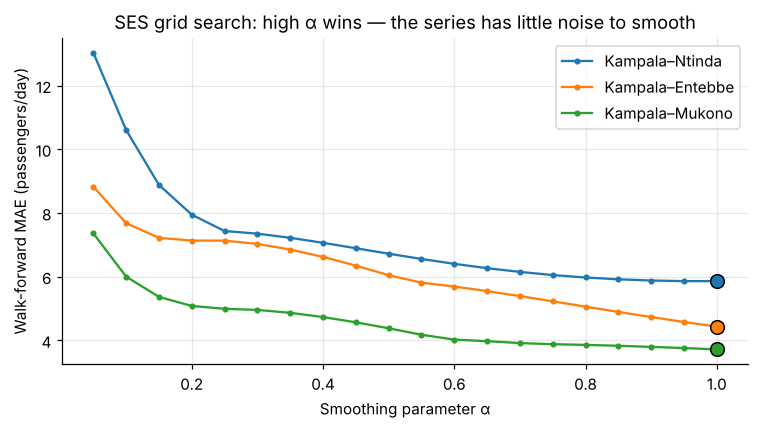

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, curve in alpha_curves.items():
    ax.plot(ALPHAS, curve, marker="o", ms=3, label=name)
    ax.scatter(best_alpha[name], min(curve), s=80, edgecolor="k", zorder=3)
ax.set_xlabel("Smoothing parameter α"); ax.set_ylabel("Walk-forward MAE (passengers/day)")
ax.set_title("SES grid search: high α wins — the series has little noise to smooth"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "p5_alpha_grid.png", bbox_inches="tight"); plt.show()

## 5. Day-11 forecast with the best model

In [6]:
def make_model(label: str, route: Route):
    return {"3-day MA": MovingAverageForecaster(3),
            "SES (tuned α)": SimpleExpSmoothingForecaster(best_alpha[route.name]),
            "Linear trend": LinearTrendForecaster()}[label]

day11 = {}
for r in routes:
    label = mae_table.loc[r.name, "best"]
    pax = float(make_model(label, r).fit(r.passengers).predict(1)[0])
    day11[r.name] = {"model": label, "pax day 11": pax, "revenue day 11 (UGX)": pax * r.fare,
                     "backtest MAE (pax)": mae_table.loc[r.name, label],
                     "± revenue (UGX)": mae_table.loc[r.name, label] * r.fare}
day11_df = pd.DataFrame(day11).T
day11_df

,model,pax day 11,revenue day 11 (UGX),backtest MAE (pax),± revenue (UGX)
Kampala–Ntinda,SES (tuned α),45.000,"90,000.000",5.857,"11,714.286"
Kampala–Entebbe,SES (tuned α),64.000,"320,000.000",4.429,"22,142.857"
Kampala–Mukono,SES (tuned α),50.000,"150,000.000",3.714,"11,142.857"


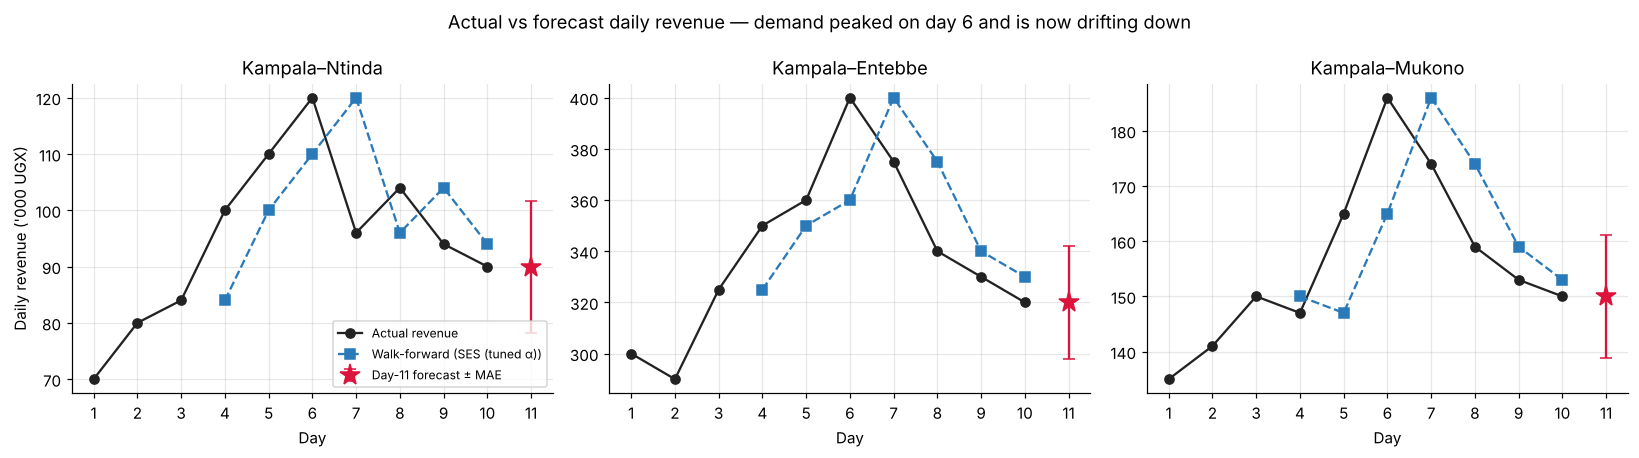

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
days = np.arange(1, 11)
for ax, r in zip(axes, routes):
    label = mae_table.loc[r.name, "best"]
    key = [k for k in backtests if k[0] == r.name and k[1].startswith(label.split(" (")[0])][0]
    ax.plot(days, r.daily_revenue() / 1000, "o-", color="#222", label="Actual revenue")
    ax.plot(days[FIRST:], backtests[key] * r.fare / 1000, "s--", color="#2a7ab9", label=f"Walk-forward ({label})")
    ax.errorbar(11, day11[r.name]["revenue day 11 (UGX)"] / 1000, yerr=day11[r.name]["± revenue (UGX)"] / 1000,
                fmt="*", ms=14, color="crimson", capsize=4, label="Day-11 forecast ± MAE")
    ax.set_title(r.name); ax.set_xlabel("Day"); ax.set_xticks(range(1, 12))
axes[0].set_ylabel("Daily revenue ('000 UGX)")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Actual vs forecast daily revenue — demand peaked on day 6 and is now drifting down")
fig.tight_layout(); fig.savefig(FIG / "p5_revenue_forecast.png", bbox_inches="tight"); plt.show()

## 6. Fleet planning for day 11

Capacity per vehicle = 8 one-way trips × 14 seats = 112 passengers/day. Vehicles = ⌈forecast × 1.15 / 112⌉.
I round **up** (a fraction of a vehicle cannot be deployed and under-supply loses fares) and also report the
peak-day requirement as a sensitivity check.

In [8]:
fleet = FleetPlanner(trips_per_day=8, seats=14, buffer=0.15)
plan = []
for r in routes:
    f = day11[r.name]["pax day 11"]
    plan.append({"route": r.name, "forecast pax": f, "with 15% buffer": f * 1.15,
                 "vehicles (day 11)": fleet.vehicles(f), "load factor": f / (fleet.vehicles(f) * fleet.capacity_per_vehicle),
                 "vehicles for 10-day peak": fleet.vehicles(r.passengers.max())})
pd.DataFrame(plan).set_index("route").round(2)

,forecast pax,with 15% buffer,vehicles (day 11),load factor,vehicles for 10-day peak
route,,,,,
Kampala–Ntinda,45.000,51.750,1,0.400,1
Kampala–Entebbe,64.000,73.600,1,0.570,1
Kampala–Mukono,50.000,57.500,1,0.450,1


Each route needs only **one vehicle** — at 8 trips × 14 seats one matatu carries 112 passengers, more than the
46–66 passengers forecast. The load factor (~40–60 %) means the vehicle would often run half-empty. This tells us
the passenger counts are probably *per vehicle or per sampled hour*, not the whole route's demand (the Ntinda
road carries thousands a day). If the counts are per trip, then demand is ~8× larger and the formula should
be applied to that total. The answer is only as good as the definition of the data — something to confirm with the
association.

## Extension — 60 days with a weekly pattern: seasonal naïve vs moving average

Synthetic counts (seed 11) with day-of-week multipliers: Fri × 1.35, Sat × 1.10, Sun × 0.60, weekdays ≈ 1.0,
plus N(0, 3) noise. Both models are back-tested one step ahead from day 15 to day 60 (46 forecasts).

,MAE
model,
Seasonal naïve (m=7),2.910
7-day MA,7.060
SES α=0.5,8.340
3-day MA,8.390


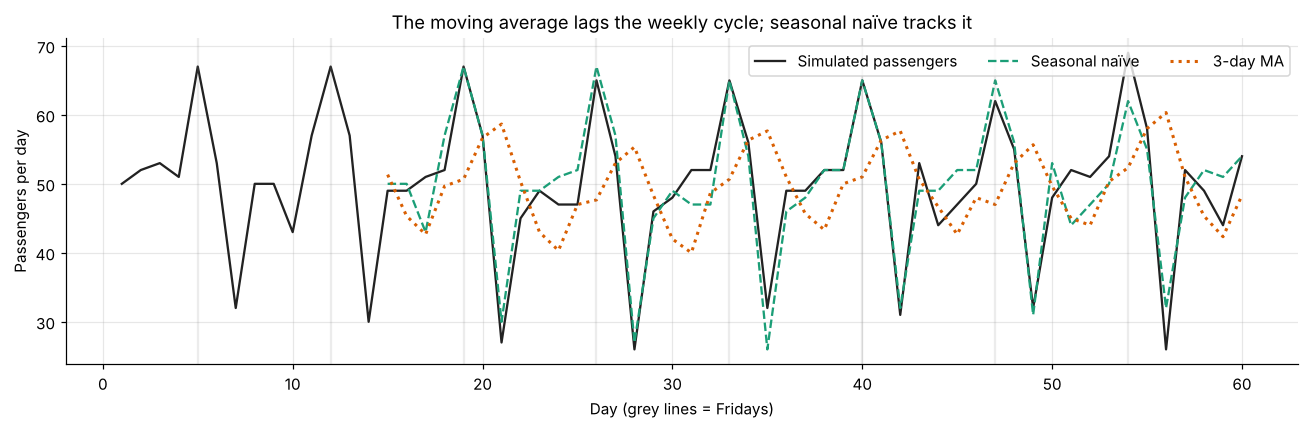

In [9]:
sim = simulate_weekly_passengers(days=60, base=50, seed=11)
contenders = {"3-day MA": MovingAverageForecaster(3), "7-day MA": MovingAverageForecaster(7),
              "Seasonal naïve (m=7)": SeasonalNaiveForecaster(7),
              f"SES α=0.5": SimpleExpSmoothingForecaster(0.5)}
ext_rows, ext_preds = [], {}
for name, model in contenders.items():
    actual, pred = walk_forward(model, sim, first_target=14)
    ext_preds[name] = pred
    ext_rows.append({"model": name, "MAE": mae(actual, pred)})
ext_df = pd.DataFrame(ext_rows).set_index("model").sort_values("MAE")
display(ext_df.round(2))

fig, ax = plt.subplots(figsize=(12, 4))
d = np.arange(1, 61)
ax.plot(d, sim, color="#222", lw=1.5, label="Simulated passengers")
ax.plot(d[14:], ext_preds["Seasonal naïve (m=7)"], "--", color="#1b9e77", label="Seasonal naïve")
ax.plot(d[14:], ext_preds["3-day MA"], ":", color="#d95f02", lw=2, label="3-day MA")
for fri in d[(d - 1) % 7 == 4]:
    ax.axvline(fri, color="grey", alpha=0.15)
ax.set_xlabel("Day (grey lines = Fridays)"); ax.set_ylabel("Passengers per day")
ax.set_title("The moving average lags the weekly cycle; seasonal naïve tracks it")
ax.legend(ncol=3)
fig.tight_layout(); fig.savefig(FIG / "p5_seasonal_naive.png", bbox_inches="tight"); plt.show()

## Findings & Limitations

**Findings.** Entebbe is the association's most valuable route: it earns UGX 339,000 a day, 3.6× Ntinda, because it
combines the highest fare with the most passengers. Ntinda carries fewer passengers but is the most variable (sd
7.4 per day). The supply–demand model says Ntinda's UGX 2,000 fare sits UGX 200 below the market-clearing
UGX 2,200, so at peak hours about 10 passengers per trip-hour cannot get a seat. The association can either let
fares rise towards UGX 2,200 or, better for commuters, add vehicles at peak times.

In walk-forward testing, the tuned SES beat the original 3-day moving average on every route, cutting MAE by
22–38 %. But the tuned α was 1.0, which is simply "tomorrow = today". All three series rose to a peak on day 6 and
have drifted down since; averaging methods lag those turns, and a linear trend fitted to a rise-then-fall series
points in the wrong direction. Day-11 forecasts are 45, 64 and 50 passengers (UGX 90k, 320k and 150k), each about
±4–6 passengers. One vehicle per route is enough even with the 15 % buffer, at 40–57 % load.

The 60-day extension shows why the original method fails on realistic data: with a Friday peak and Sunday dip,
seasonal naïve (MAE 2.9) beat the 3-day MA (8.4) by almost 3×, because the moving average smears the weekly cycle.

**Limitations.** Ten days is far too short to tune or validate a model; α = 1 could easily change with more data.
The demand and supply curves are given, not estimated, and the "trip-hour" units do not match the daily counts. The
fleet result hinges on what a passenger count measures (per vehicle? per trip? per route?), which the data do not
say. Fares, fuel costs and travel times are fixed.